# Anexo: ResNet-18 e CNN do zero (execução A)

Faculdade de Ciências e Tecnologias em Engenharia - Campus UnB Gama <br>
Tópicos Especiais em Matemática Aplicada: Deep Learning <br>
Professor: Vinicius Rispoli<br>
Alunos: Eliseu Kadesh, Pedro Barbosa e Raquel Eucaria.

## 1. Dados

Usa a divisão treino/validação/teste em `data/passaros/dataset_split`, criada uma única vez e reutilizada pelos três notebooks. Rode o [notebook 01](01_classificador_vit_h14.ipynb) antes.

In [ ]:
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from tqdm import tqdm
import matplotlib.pyplot as plt
import os

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Configurar o dispositivo (GPU, se disponível)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

Usando dispositivo: cuda


In [ ]:
data_dir = "data/passaros/dataset_split"

train_dir = os.path.join(data_dir, 'train')
val_dir = os.path.join(data_dir, 'val')
test_dir = os.path.join(data_dir, 'test')

### Classes

In [ ]:
# Listar as classes (espécies de aves)
classes = sorted(os.listdir(train_dir)) # Ordenar para consistência
num_classes = len(classes)
print(f"Número de classes: {num_classes}")
print("Classes:", classes)


Número de classes: 14
Classes: ['amazona_aestiva', 'amazona_amazonica', 'anodorhynchus_hyacinthinus', 'ara_ararauna', 'ara_chloropterus', 'ara_macao', 'brotogeris_chiriri', 'diopsittaca_nobilis', 'eupsittula_aurea', 'forpus_xanthopterygius', 'orthopsittaca_manilatus', 'primolius_maracana', 'psittacara_leucophthalmus', 'touit_melanonotus']


### Pré-processamento

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

# Médias e desvios padrão da ImageNet
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Transformações para os conjuntos de validação e teste (sem data augmentation)
transform_val_test = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

### Data augmentation e DataLoaders

In [ ]:
# Transformações para o conjunto de treino (com data augmentation)
transform_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5), # Vira a imagem horizontalmente
    transforms.RandomRotation(degrees=20),    # Rotaciona a imagem em até 20 graus
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2), # Altera cor e brilho
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

# Carregar os datasets usando ImageFolder
train_dataset = datasets.ImageFolder(train_dir, transform=transform_train)
val_dataset = datasets.ImageFolder(val_dir, transform=transform_val_test)
test_dataset = datasets.ImageFolder(test_dir, transform=transform_val_test)

# Criar os DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Tamanho do dataset de treino: {len(train_dataset)} imagens")
print(f"Tamanho do dataset de validação: {len(val_dataset)} imagens")
print(f"Tamanho do dataset de teste: {len(test_dataset)} imagens")

Tamanho do dataset de treino: 2425 imagens
Tamanho do dataset de validação: 304 imagens
Tamanho do dataset de teste: 308 imagens


## 2. Treino

### Funções de treino e avaliação

Adaptadas das funções vistas em aula.

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(loader, desc='Treino', leave=False)
    for inputs, targets in pbar:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total   += targets.size(0)
        correct += predicted.eq(targets).sum().item()

        pbar.set_postfix({'loss': running_loss / total, 'acc': 100.*correct/total})

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc  = 100. * correct / total
    return epoch_loss, epoch_acc

def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        pbar = tqdm(loader, desc='Validação', leave=False)
        for inputs, targets in pbar:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            running_loss += loss.item() * inputs.size(0)

            _, predicted = outputs.max(1)
            total   += targets.size(0)
            correct += predicted.eq(targets).sum().item()
            pbar.set_postfix({'loss': running_loss/total, 'acc': 100.*correct/total})

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc  = 100. * correct / total
    return epoch_loss, epoch_acc

### CNN do zero (execução A)

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=14):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)

        # A imagem de 224x224 passa por 3 poolings: 224 -> 112 -> 56 -> 28
        self.fc1 = nn.Linear(64 * 28 * 28, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = x.view(-1, 64 * 28 * 28)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instanciar e treinar o modelo
cnn_scratch = SimpleCNN(num_classes=num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_scratch.parameters(), lr=0.001)
epochs_scratch = 15

print("Iniciando Treinamento da CNN do Zero...")
for epoch in range(epochs_scratch):
    print(f"\nÉpoca {epoch+1}/{epochs_scratch}")
    train_loss, train_acc = train_one_epoch(cnn_scratch, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(cnn_scratch, val_loader, criterion, device)
    print(f"  Loss de Treino: {train_loss:.4f}, Acurácia de Treino: {train_acc:.2f}%")
    print(f"  Loss de Validação: {val_loss:.4f}, Acurácia de Validação: {val_acc:.2f}%")

Iniciando Treinamento da CNN do Zero...

Época 1/15
  Loss de Treino: 7.9096, Acurácia de Treino: 7.59%
  Loss de Validação: 2.6267, Acurácia de Validação: 7.24%

Época 2/15
  Loss de Treino: 2.6402, Acurácia de Treino: 7.63%
  Loss de Validação: 2.6365, Acurácia de Validação: 8.22%

Época 3/15
  Loss de Treino: 2.6414, Acurácia de Treino: 8.54%
  Loss de Validação: 2.6344, Acurácia de Validação: 7.57%

Época 4/15
  Loss de Treino: 2.6351, Acurácia de Treino: 8.74%
  Loss de Validação: 2.6326, Acurácia de Validação: 7.89%

Época 5/15
  Loss de Treino: 2.6367, Acurácia de Treino: 8.54%
  Loss de Validação: 2.6354, Acurácia de Validação: 8.22%

Época 6/15
  Loss de Treino: 2.6351, Acurácia de Treino: 8.37%
  Loss de Validação: 2.6332, Acurácia de Validação: 8.22%

Época 7/15
  Loss de Treino: 2.6339, Acurácia de Treino: 8.82%
  Loss de Validação: 2.6320, Acurácia de Validação: 8.22%

Época 8/15
  Loss de Treino: 2.6340, Acurácia de Treino: 8.29%
  Loss de Validação: 2.6308, Acurácia de V

### ResNet-18: extração de características

Pesos da ImageNet congelados; só o novo classificador é treinado, por 10 épocas.

In [ ]:
model_tl = models.resnet18(weights='IMAGENET1K_V1')

# Congelar os pesos das camadas pré-treinadas
for param in model_tl.parameters():
    param.requires_grad = False

# Substituir a camada de classificação (fully connected)
num_ftrs = model_tl.fc.in_features
model_tl.fc = nn.Linear(num_ftrs, num_classes)

model_tl = model_tl.to(device)

# Otimizador para treinar APENAS a nova camada
optimizer_tl = optim.Adam(model_tl.fc.parameters(), lr=0.001)
epochs_tl = 10

print("Iniciando Treinamento com Transfer Learning (Feature Extraction)...")
for epoch in range(epochs_tl):
    print(f"\nÉpoca {epoch+1}/{epochs_tl}")
    train_loss, train_acc = train_one_epoch(model_tl, train_loader, criterion, optimizer_tl, device)
    val_loss, val_acc = evaluate(model_tl, val_loader, criterion, device)
    print(f"  Loss de Treino: {train_loss:.4f}, Acurácia de Treino: {train_acc:.2f}%")
    print(f"  Loss de Validação: {val_loss:.4f}, Acurácia de Validação: {val_acc:.2f}%")

Iniciando Treinamento com Transfer Learning (Feature Extraction)...

Época 1/10
  Loss de Treino: 2.4108, Acurácia de Treino: 20.04%
  Loss de Validação: 2.0480, Acurácia de Validação: 32.89%

Época 2/10
  Loss de Treino: 1.9668, Acurácia de Treino: 38.47%
  Loss de Validação: 1.8463, Acurácia de Validação: 40.46%

Época 3/10
  Loss de Treino: 1.7541, Acurácia de Treino: 45.03%
  Loss de Validação: 1.6818, Acurácia de Validação: 44.41%

Época 4/10
  Loss de Treino: 1.6092, Acurácia de Treino: 49.24%
  Loss de Validação: 1.6156, Acurácia de Validação: 45.07%

Época 5/10
  Loss de Treino: 1.5626, Acurácia de Treino: 50.80%
  Loss de Validação: 1.6014, Acurácia de Validação: 45.07%

Época 6/10
  Loss de Treino: 1.4953, Acurácia de Treino: 52.12%
  Loss de Validação: 1.5155, Acurácia de Validação: 52.63%

Época 7/10
  Loss de Treino: 1.4508, Acurácia de Treino: 53.48%
  Loss de Validação: 1.5021, Acurácia de Validação: 49.67%

Época 8/10
  Loss de Treino: 1.4027, Acurácia de Treino: 55.05%

### ResNet-18: fine-tuning

Rede inteira descongelada, lr 1e-5, 15 épocas.

In [ ]:
# Descongelar todas as camadas para o fine-tuning
for param in model_tl.parameters():
    param.requires_grad = True

# Otimizador para o modelo inteiro com uma taxa de aprendizado baixa
optimizer_ft = optim.Adam(model_tl.parameters(), lr=1e-5)
epochs_ft = 15
model_fine_tuned = model_tl # Renomeando para clareza

print("\nIniciando Treinamento com Fine-Tuning...")
for epoch in range(epochs_ft):
    print(f"\nÉpoca {epoch+1}/{epochs_ft}")
    train_loss, train_acc = train_one_epoch(model_fine_tuned, train_loader, criterion, optimizer_ft, device)
    val_loss, val_acc = evaluate(model_fine_tuned, val_loader, criterion, device)
    print(f"  Loss de Treino: {train_loss:.4f}, Acurácia de Treino: {train_acc:.2f}%")
    print(f"  Loss de Validação: {val_loss:.4f}, Acurácia de Validação: {val_acc:.2f}%")


Iniciando Treinamento com Fine-Tuning...

Época 1/15
  Loss de Treino: 1.2269, Acurácia de Treino: 61.03%
  Loss de Validação: 1.2890, Acurácia de Validação: 55.92%

Época 2/15
  Loss de Treino: 1.0966, Acurácia de Treino: 66.06%
  Loss de Validação: 1.1913, Acurácia de Validação: 62.50%

Época 3/15
  Loss de Treino: 1.0163, Acurácia de Treino: 68.82%
  Loss de Validação: 1.1372, Acurácia de Validação: 65.46%

Época 4/15
  Loss de Treino: 0.9311, Acurácia de Treino: 71.26%
  Loss de Validação: 1.0714, Acurácia de Validação: 67.76%

Época 5/15
  Loss de Treino: 0.8509, Acurácia de Treino: 73.32%
  Loss de Validação: 1.0413, Acurácia de Validação: 66.78%

Época 6/15
  Loss de Treino: 0.7942, Acurácia de Treino: 77.57%
  Loss de Validação: 1.0059, Acurácia de Validação: 70.07%

Época 7/15
  Loss de Treino: 0.7489, Acurácia de Treino: 78.52%
  Loss de Validação: 0.9689, Acurácia de Validação: 70.39%

Época 8/15
  Loss de Treino: 0.7088, Acurácia de Treino: 79.22%
  Loss de Validação: 0.97

## 3. Avaliação no teste interno (308 imagens)

In [ ]:
# Função para obter predições e rótulos do conjunto de teste
def get_predictions(model, loader, device):
    model.eval()
    all_preds = torch.tensor([]).to(device)
    all_labels = torch.tensor([]).to(device)
    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc="Avaliando no Teste"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds = torch.cat((all_preds, preds), dim=0)
            all_labels = torch.cat((all_labels, labels), dim=0)
    return all_labels.cpu().numpy(), all_preds.cpu().numpy()

class_names = train_dataset.classes

In [ ]:
print("--- Relatório de Classificação: CNN do Zero ---")
labels_scratch, preds_scratch = get_predictions(cnn_scratch, test_loader, device)
print(classification_report(labels_scratch, preds_scratch, target_names=class_names))

print("\n--- Relatório de Classificação: Modelo com Fine-Tuning ---")
labels_ft, preds_ft = get_predictions(model_fine_tuned, test_loader, device)
print(classification_report(labels_ft, preds_ft, target_names=class_names))

--- Relatório de Classificação: CNN do Zero ---
                            precision    recall  f1-score   support

           amazona_aestiva       0.00      0.00      0.00        25
         amazona_amazonica       0.00      0.00      0.00        21
anodorhynchus_hyacinthinus       0.08      0.96      0.15        25
              ara_ararauna       0.00      0.00      0.00        25
          ara_chloropterus       0.42      0.23      0.29        22
                 ara_macao       0.00      0.00      0.00        22
        brotogeris_chiriri       0.00      0.00      0.00        20
       diopsittaca_nobilis       1.00      0.04      0.08        24
          eupsittula_aurea       0.00      0.00      0.00        22
    forpus_xanthopterygius       0.00      0.00      0.00        22
   orthopsittaca_manilatus       0.00      0.00      0.00        20
        primolius_maracana       0.00      0.00      0.00        22
 psittacara_leucophthalmus       0.00      0.00      0.00        23

### Matriz de confusão (ResNet-18)

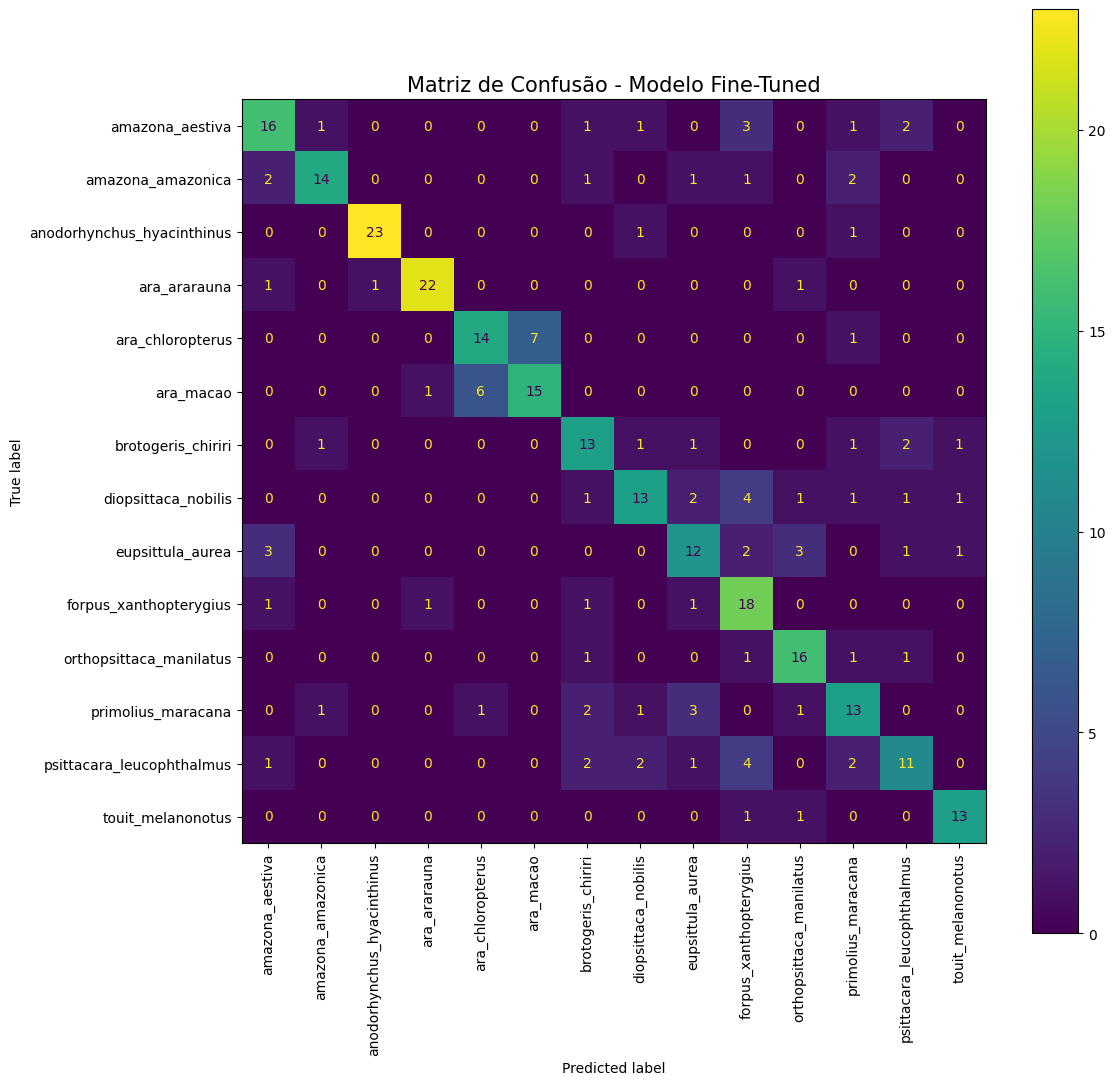

In [ ]:
def plot_confusion_matrix(labels, preds, class_names, title):
    cm = confusion_matrix(labels, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(12, 12))
    disp.plot(ax=ax, xticks_rotation='vertical', cmap='viridis')
    ax.set_title(title, fontsize=15)
    plt.show()

plot_confusion_matrix(labels_ft, preds_ft, class_names, 'Matriz de Confusão - Modelo Fine-Tuned')